# PathPack v0.6

Первая часть проверяет интеграцию на искусственном репозитории `examples/v06_demo`: длинная функция, нужные слова стоят в конце. Это не результат SWE-bench.

Вторая часть читает прогон `output/v06_dev` на 20 dev-задачах. v0.4 остаётся основной версией: File Recall v0.6 ниже, а прирост Changed Line Recall не выходит за парный интервал, включающий ноль.


In [1]:
from pathlib import Path
import sys
ROOT=Path.cwd().resolve()
if not (ROOT/'src').exists():
    ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
from codegraph_rag.parser import scan_repository
from codegraph_rag.retrieval import retrieve
from codegraph_rag.pathpack_v6 import make_v6_chunks
SRC=ROOT/'examples/v06_demo/snapshot'
graph=scan_repository(SRC)
fine=make_v6_chunks(SRC,graph,target_tokens=80,max_chunk_tokens=140)
print('nodes',len(graph.nodes),'edges',len(graph.edges),'fine',len(fine))
slices=[c for c in fine if c.qualname=='validate_cookie']
print('validate_cookie slices',len(slices))
print([(c.line_start,c.line_end,'expired_session_signature' in c.body) for c in slices])


nodes 6 edges 6 fine 9
validate_cookie slices 7
[(1, 13, False), (12, 25, False), (24, 37, False), (36, 49, False), (48, 61, False), (60, 73, False), (72, 84, True)]


## Граф учебного примера

Рёбра `calls` построены из AST этого примера. Это не граф задачи SWE-bench.


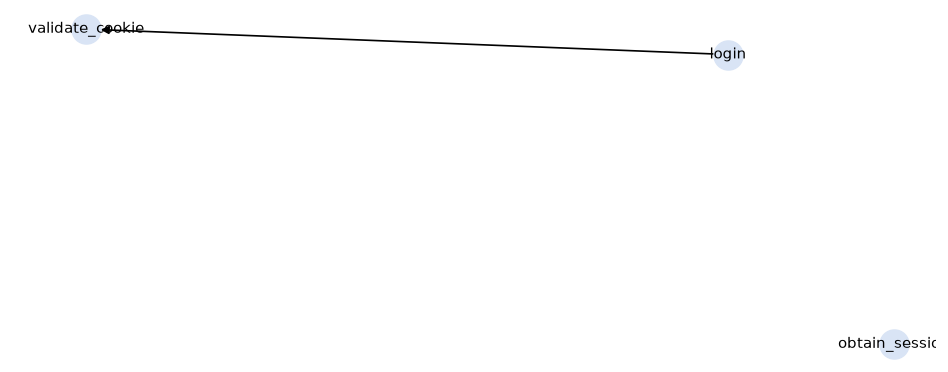

In [2]:
import matplotlib.pyplot as plt
import networkx as nx
G=nx.DiGraph()
funcs={k:v for k,v in graph.nodes.items() if v.kind in ('function','method')}
for key,value in funcs.items():
    G.add_node(key,label=value.qualname)
for edge in graph.edges:
    if edge.kind=='calls' and edge.source in funcs and edge.target in funcs:
        G.add_edge(edge.source,edge.target)
fig,ax=plt.subplots(figsize=(8,3.2))
pos=nx.spring_layout(G,seed=42)
nx.draw_networkx(G,pos,ax=ax,labels={n:funcs[n].qualname for n in G},node_color='#d9e4f5',font_size=9,arrows=True)
ax.set_axis_off()
fig.tight_layout()
plt.show()


## Срез, а не начало функции

Запрос говорит про просроченную подпись. Целая функция длиннее 180 токенов, поэтому BM25 и v0.3 при этом бюджете её не вмещают. v0.6 кладёт в контекст срез со строками 71–84, где стоит `expired_session_signature`.


In [3]:
query='expired session signature invalid cookie'
for method in ['bm25','pathpack-v3','pathpack-v6']:
    _,hits=retrieve(SRC,query,method=method,budget=180)
    text=''.join(h.chunk.text for h in hits)
    print(method,'chunks',len(hits),'has marker', 'expired_session_signature' in text,
          'lines',[(h.chunk.line_start,h.chunk.line_end) for h in hits])


bm25 chunks 2 has marker False lines [(None, None), (None, None)]
pathpack-v3 chunks 1 has marker False lines [(None, None)]
pathpack-v6 chunks 3 has marker True lines [(3, 4), (71, 84), (1, 2)]


## 20 dev-задач, бюджет 2048

Числа читаются из `output/v06_dev/summary.csv`. Число оцениваемых задач: File 20, Function и Complete 18, Changed Line 14.


method                          file      fn complete    line  latency
bm25                           0.350   0.111    0.111   0.143    0.056
graph-expand                   0.325   0.111    0.111   0.143    0.162
pathpack-v4                    0.725   0.202    0.091   0.148    0.615
pathpack-v51                   0.625   0.198    0.087   0.172    0.996
pathpack-v6                    0.600   0.226    0.060   0.172    2.504
pathpack-v6/hops-1             0.625   0.179    0.067   0.172    2.450
pathpack-v6/hops-2             0.575   0.175    0.063   0.172    2.424
pathpack-v6/callers            0.625   0.115    0.060   0.172    2.458
pathpack-v6/callees            0.625   0.234    0.067   0.172    2.429
pathpack-v6/no-graph           0.625   0.115    0.060   0.172    2.403
pathpack-v6/no-parent          0.700   0.226    0.060   0.172    2.485
pathpack-v6/no-chunking        0.500   0.226    0.226   0.148    2.121
pathpack-v6/no-diversity       0.450   0.222    0.083   0.180    2.235


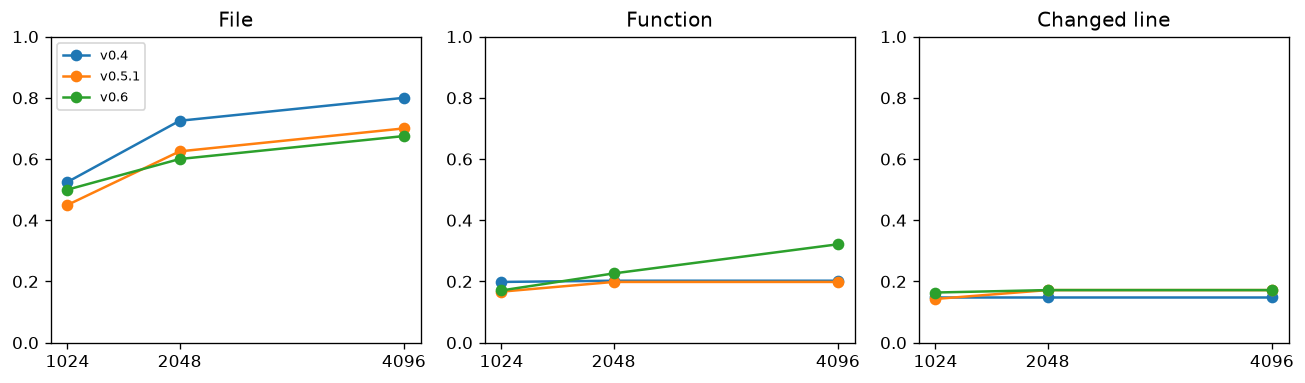

In [4]:
import csv
def load(path):
    with open(path,newline='') as f:
        return list(csv.DictReader(f))
rows=load(ROOT/'output/v06_dev/summary.csv')
want=['bm25','graph-expand','pathpack-v4','pathpack-v51','pathpack-v6','pathpack-v6/hops-1','pathpack-v6/hops-2','pathpack-v6/callers','pathpack-v6/callees','pathpack-v6/no-graph','pathpack-v6/no-parent','pathpack-v6/no-chunking','pathpack-v6/no-diversity']
print(f"{'method':<28} {'file':>7} {'fn':>7} {'complete':>8} {'line':>7} {'latency':>8}")
for method in want:
    r=next(item for item in rows if item['method']==method and item['budget']=='2048')
    print(f"{method:<28} {float(r['file_recall']):7.3f} {float(r['function_recall']):7.3f} {float(r['complete_function_recall']):8.3f} {float(r['changed_line_recall']):7.3f} {float(r['latency_sec']):8.3f}")
fig,axes=plt.subplots(1,3,figsize=(11,3.3),sharex=True)
for ax,(key,title) in zip(axes,[('file_recall','File'),('function_recall','Function'),('changed_line_recall','Changed line')]):
    for method,label in [('pathpack-v4','v0.4'),('pathpack-v51','v0.5.1'),('pathpack-v6','v0.6')]:
        series=sorted((item for item in rows if item['method']==method), key=lambda item:int(item['budget']))
        ax.plot([int(item['budget']) for item in series],[float(item[key]) for item in series],marker='o',label=label)
    ax.set_title(title); ax.set_xticks([1024,2048,4096]); ax.set_ylim(0,1)
axes[0].legend(fontsize=8)
fig.tight_layout(); plt.show()


## Парное сравнение

Разница — v0.6 минус v0.4, по одним и тем же задачам. Интервал, который включает 0, не считается подтверждением.


In [5]:
import json
comp=json.loads((ROOT/'output/v06_dev/comparisons.json').read_text())
print(f"{'metric':<28} {'diff':>8} {'ci':>24} {'+/=/-':>10}")
for item in comp:
    if item.get('candidate')=='pathpack-v6' and item.get('baseline')=='pathpack-v4' and item['budget']==2048:
        lo,hi=item['ci95']
        print(f"{item['metric']:<28} {item['difference']:8.4f} [{lo:7.3f}, {hi:7.3f}] {item['wins']:>3}/{item['ties']:>2}/{item['losses']}")


metric                           diff                       ci      +/=/-
file_recall                   -0.1250 [ -0.325,   0.050]   1/15/4
function_recall                0.0238 [ -0.083,   0.163]   1/15/2
complete_function_recall      -0.0317 [ -0.087,   0.000]   0/16/2
changed_line_recall            0.0238 [  0.000,   0.071]   1/13/0
relevant_line_density         -0.0111 [ -0.036,   0.012]   1/ 4/3


## Вывод

На учебном примере v0.6 доходит до строки внутри длинной функции. На 20 dev-задачах при 2048 токенах он проигрывает v0.4 по File Recall (0.600 против 0.725) и не даёт прироста Changed Line Recall, чей интервал включает ноль. Holdout не запускался. Конфигурация после прогона не менялась.
